# Pipeline Complet : Fine-Tuning + Évaluation — Dataset DMID
## EfficientNet-B3 · U-Net · SAM vs Ground-Truth

| Étape | Description |
|---|---|
| **1** | Nettoyage metadata + split train/val/test par image |
| **2** | Fine-tuning **EfficientNet-B3** sur crops GT (cx,cy,radius) |
| **3** | Fine-tuning **U-Net** sur masques circulaires GT |
| **4** | Évaluation **SAM** : IoU vs cercles ground-truth |
| **5** | Comparaison pipeline GT crop vs SAM crop → EfficientNet |

**Dataset** : DMID — 276 images uniques, 411 annotations B/M, résolution 512×512


## Étape 0 — Montage Google Drive

Lance cette cellule **uniquement sur Google Colab**.
Structure attendue dans ton Drive :
```
MyDrive/
└── PFA/
    ├── DMID/
    │   ├── metadata.xlsx
    │   ├── 512/
    │   │   ├── tiff/      ← images PNG mammographies
    │   │   └── masks/     ← masques (non utilisés directement)
    │   └── 1024/          ← optionnel
    └── models/            ← créé automatiquement
```


In [44]:
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Drive monté.')
else:
    print('Environnement local — Drive non nécessaire.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive monté.


In [45]:
!pip install -q timm segmentation-models-pytorch
!pip install -q transformers accelerate bitsandbytes
!pip install -q openpyxl scikit-learn matplotlib seaborn
!pip install -q imbalanced-learn


In [46]:
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image, ImageDraw
from numpy.lib.stride_tricks import sliding_window_view

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

import timm
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                              confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
torch.manual_seed(42); np.random.seed(42); random.seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


In [47]:
# ── Adapter ces chemins selon ton environnement ──────────────────────────────
PFA_PATH     = '/content/drive/MyDrive/PFA'   # Colab
# PFA_PATH   = r'd:\\PFA'                    # Local Windows

DATASET_PATH = os.path.join(PFA_PATH, 'DMID')
METADATA_XLS = os.path.join(DATASET_PATH, 'Metadata.xlsx')
IMG_DIR      = os.path.join(DATASET_PATH, '512', 'TIFF')
MASK_DIR     = os.path.join(DATASET_PATH, '512', 'Mask')
MODELS_DIR   = os.path.join(PFA_PATH, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

# EfficientNet
EFF_SIZE     = 300
EFF_BATCH    = 16
EFF_LR_HEAD  = 1e-3
EFF_LR_BACK  = 1e-4
EFF_EPOCHS   = 30
EFF_PATIENCE = 8
# PAD=3.0 → crop = lésion + 200% de tissu environnant → contexte suffisant
# Cohérence pipeline : SAM crop ≈ GT crop (même type d'entrée à l'inférence)
EFF_PAD      = 3.0

# U-Net
SEG_SIZE     = 256
SEG_BATCH    = 8
SEG_LR       = 1e-4
SEG_EPOCHS   = 30
SEG_PATIENCE = 8

# SAM de base : toujours facebook/sam-vit-base (vrai SAM original, zero-shot)
# C'est le point de départ pour notre fine-tuning ET la baseline de comparaison.
# ayoubkirouane est déjà fine-tuné sur breast cancer → évalué séparément.
SAM_BASE_ID = 'facebook/sam-vit-base'
SAM_EXT_ID  = 'ayoubkirouane/Breast-Cancer_SAM_v1'  # comparaison externe optionnelle
SAM_ID      = SAM_BASE_ID  # utilisé dans sam_run
print('Configuration OK')
print(f'  Modèles → {MODELS_DIR}')


Configuration OK
  Modèles → /content/drive/MyDrive/PFA/models


In [48]:
# ── Chargement et nettoyage ──────────────────────────────────────────────────
# Les 31 premières lignes sont des descriptions (légende des colonnes).
# Les données réelles commencent à la ligne 32 (skiprows=31).
df_raw = pd.read_excel(METADATA_XLS, header=None, skiprows=31,
                       names=['ref','view','tissue','abnormality',
                               'class','cx','cy','radius'])

VALID = {'B','M','N'}
df = df_raw[df_raw['class'].astype(str).str.strip().isin(VALID)].copy()
df['class']  = df['class'].astype(str).str.strip()
df['ref']    = df['ref'].astype(str).str.strip()
df['cx']     = pd.to_numeric(df['cx'],     errors='coerce')
df['cy']     = pd.to_numeric(df['cy'],     errors='coerce')
df['radius'] = pd.to_numeric(df['radius'], errors='coerce')

df_bm = df[df['class'].isin(['B','M'])].dropna(subset=['cx','cy','radius']).copy()
df_bm['label'] = (df_bm['class'] == 'M').astype(int)

print(f'Lignes nettoyées   : {len(df)}')
print(f'Annotations B+M    : {len(df_bm)}')
print(f'  Benign     : {(df_bm.label==0).sum()}')
print(f'  Malignant  : {(df_bm.label==1).sum()}')
print(f'Images uniques     : {df_bm["ref"].nunique()}')
print(f'Lésions/image moy  : {len(df_bm)/df_bm["ref"].nunique():.2f}')
print(f'\nPlage coordonnées brutes :')
print(f'  cx     : {df_bm["cx"].min():.0f} → {df_bm["cx"].max():.0f}')
print(f'  cy     : {df_bm["cy"].min():.0f} → {df_bm["cy"].max():.0f}')
print(f'  radius : {df_bm["radius"].min():.0f} → {df_bm["radius"].max():.0f}')


Lignes nettoyées   : 447
Annotations B+M    : 408
  Benign     : 253
  Malignant  : 155
Images uniques     : 274
Lésions/image moy  : 1.49

Plage coordonnées brutes :
  cx     : 28 → 4697
  cy     : 680 → 35561
  radius : 20 → 2355


In [49]:
# ── Split par image (ref) — évite fuite entre vues du même patient ───────────
ref_cls = (df_bm.groupby('ref')['class']
             .agg(lambda x: x.mode()[0]).reset_index())
refs, labels = ref_cls['ref'].values, ref_cls['class'].values

r_train, r_temp, _, l_temp = train_test_split(
    refs, labels, test_size=0.30, stratify=labels, random_state=42)
r_val, r_test, _, _ = train_test_split(
    r_temp, l_temp, test_size=0.50, stratify=l_temp, random_state=42)

# ── DataFrame niveau LÉSION (cx/cy/radius) → utilisé pour U-Net + SAM ────────
train_df = df_bm[df_bm['ref'].isin(r_train)].reset_index(drop=True)
val_df   = df_bm[df_bm['ref'].isin(r_val)].reset_index(drop=True)
test_df  = df_bm[df_bm['ref'].isin(r_test)].reset_index(drop=True)

# ── DataFrame niveau IMAGE → utilisé pour EfficientNet ────────────────────────
# Règle : si au moins une lésion est Maligne → image = Maligne
def make_img_df(df_crops):
    rows = []
    for ref, grp in df_crops.groupby('ref'):
        rows.append({'ref': ref, 'label': int(grp['label'].max())})
    return pd.DataFrame(rows).reset_index(drop=True)

img_train_df = make_img_df(train_df)
img_val_df   = make_img_df(val_df)
img_test_df  = make_img_df(test_df)

print('=== Niveau LÉSION (pour U-Net / SAM) ===')
for name, dfs, refs_ in [('Train',train_df,r_train),
                          ('Val',  val_df,  r_val),
                          ('Test', test_df, r_test)]:
    b = (dfs.label==0).sum(); m = (dfs.label==1).sum()
    print(f'{name:5s}: {len(refs_):3d} images → {len(dfs):3d} lésions  (B:{b} / M:{m})')

print('\n=== Niveau IMAGE (pour EfficientNet) ===')
for name, dfi in [('Train',img_train_df),('Val',img_val_df),('Test',img_test_df)]:
    b = (dfi.label==0).sum(); m = (dfi.label==1).sum()
    print(f'{name:5s}: {len(dfi):3d} images  (B:{b} / M:{m})')


=== Niveau LÉSION (pour U-Net / SAM) ===
Train: 191 images → 280 lésions  (B:168 / M:112)
Val  :  41 images →  66 lésions  (B:42 / M:24)
Test :  42 images →  62 lésions  (B:43 / M:19)

=== Niveau IMAGE (pour EfficientNet) ===
Train: 191 images  (B:100 / M:91)
Val  :  41 images  (B:23 / M:18)
Test :  42 images  (B:23 / M:19)


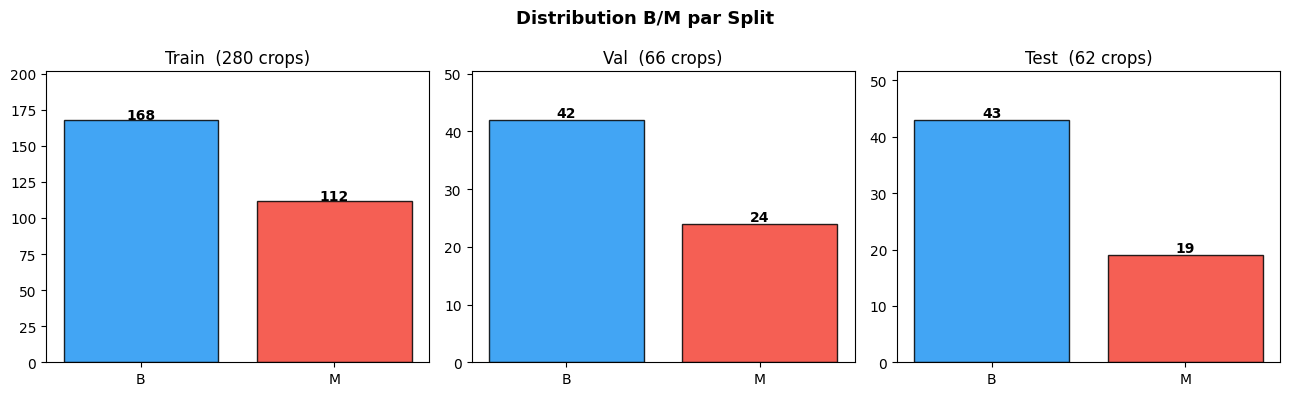

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (dfs, name) in zip(axes,
                           [(train_df,'Train'),(val_df,'Val'),(test_df,'Test')]):
    counts = dfs['class'].value_counts()
    bars = ax.bar(counts.index, counts.values,
                  color=['#2196F3','#F44336'], edgecolor='black', alpha=0.85)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                str(v), ha='center', fontweight='bold')
    ax.set_title(f'{name}  ({len(dfs)} crops)', fontsize=12)
    ax.set_ylim(0, counts.max()*1.2)
plt.suptitle('Distribution B/M par Split', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'dmid_split.png'), dpi=150, bbox_inches='tight')
plt.show()


In [51]:
def get_img_path(ref, img_dir=IMG_DIR):
    for candidate in [
        Path(img_dir)/f'{ref}.png',
        Path(img_dir)/f'{ref.upper()}.png',
        Path(img_dir)/f'{ref.lower()}.png',
    ]:
        if candidate.exists(): return str(candidate)
    hits = list(Path(img_dir).glob(f'*{ref}*.png'))
    return str(hits[0]) if hits else None

def get_mask_path(ref, mask_dir=MASK_DIR):
    for candidate in [
        Path(mask_dir)/f'{ref}.png',
        Path(mask_dir)/f'{ref.upper()}.png',
        Path(mask_dir)/f'{ref.lower()}.png',
    ]:
        if candidate.exists(): return str(candidate)
    hits = list(Path(mask_dir).glob(f'*{ref}*.png'))
    return str(hits[0]) if hits else None

def crop_gt(img_pil, cx, cy, radius, pad=EFF_PAD, sx=1.0, sy=1.0):
    W, H = img_pil.size
    cxs, cys, rs = int(cx*sx), int(cy*sy), int(radius*min(sx,sy)*pad)
    x1, y1 = max(0, cxs-rs), max(0, cys-rs)
    x2, y2 = min(W, cxs+rs), min(H, cys+rs)
    return img_pil.crop((x1,y1,x2,y2)) if x2>x1 and y2>y1 else img_pil

def gt_circle_mask(W, H, cx, cy, radius, sx=1.0, sy=1.0):
    cxs, cys = int(cx*sx), int(cy*sy)
    rs = int(radius * min(sx, sy))
    mask = Image.new('L', (W,H), 0)
    ImageDraw.Draw(mask).ellipse(
        [cxs-rs, cys-rs, cxs+rs, cys+rs], fill=255)
    return np.array(mask) > 0

def load_mask_file(ref, target_W, target_H):
    """
    Tente de charger un masque binaire depuis MASK_DIR.
    Retourne un tableau numpy bool (H,W) ou None si non trouvé/vide.
    """
    mpath = get_mask_path(ref)
    if mpath is None: return None
    m = Image.open(mpath).convert('L')
    m = m.resize((target_W, target_H), Image.NEAREST)
    arr = np.array(m)
    # Si c'est un vrai masque binaire (fond noir, lesion blanche)
    if arr.mean() < 50 and arr.max() > 20:
        return arr > 20
    # Si c'est une image annotée (mammogramme + cercle coloré) :
    # Tenter de détecter le cercle par seuil sur la luminosité
    if arr.max() > 200:
        thr = arr.max() * 0.85
        candidate = arr > thr
        ratio = candidate.mean()
        if 0.001 < ratio < 0.3:  # region raisonnable pour une lesion
            return candidate
    return None

# ── Détection automatique du facteur d'échelle des coordonnées ───────────────
# Les coordonnées (cx, cy, radius) dans le metadata DMID sont exprimées
# dans la résolution ORIGINALE des mammographies (avant redimensionnement).
# Les images PNG dans 512/tiff/ sont déjà redimensionnées en 512×512.
# Il faut donc multiplier les coordonnées par un facteur d'échelle.
#
# Formule : COORD_SX = taille_cible / taille_originale
# Estimation de taille_originale : cx_max (la lésion la plus à droite
# donne une borne inférieure de la largeur originale).
_s_ref  = df_bm['ref'].iloc[0]
_s_path = get_img_path(_s_ref)
if _s_path:
    _W, _H = Image.open(_s_path).size  # taille cible (ex : 512×512)
    _cx_max = df_bm['cx'].max()
    _cy_max = df_bm['cy'].max()
    if _cx_max > _W or _cy_max > _H:
        # Les coordonnées dépassent la taille de l'image → mise à l'échelle
        # On utilise cx_max comme estimateur de la largeur originale,
        # et cy_max comme estimateur de la hauteur originale.
        COORD_SX = _W / _cx_max
        COORD_SY = _H / _cy_max
        print(f'Coordonnees hors-limites detectees !')
        print(f'  Image cible    : {_W} x {_H} pixels')
        print(f'  cx_max metadata: {_cx_max:.0f}  →  COORD_SX = {_W}/{_cx_max:.0f} = {COORD_SX:.4f}')
        print(f'  cy_max metadata: {_cy_max:.0f}  →  COORD_SY = {_H}/{_cy_max:.0f} = {COORD_SY:.4f}')
        print(f'  Ex: cx=1000 → pixel={int(1000*COORD_SX)}  '
              f'cy=2000 → pixel={int(2000*COORD_SY)}')
    else:
        COORD_SX = COORD_SY = 1.0
        print(f'Coordonnees OK — dans les limites ({_W}x{_H})')
        print(f'  cx range: {df_bm["cx"].min():.0f} a {_cx_max:.0f}')
        print(f'  cy range: {df_bm["cy"].min():.0f} a {_cy_max:.0f}')
else:
    COORD_SX = COORD_SY = 1.0
    print('Image introuvable — facteur echelle = 1.0')

print('\nUtilitaires crop/masque OK')


Coordonnees hors-limites detectees !
  Image cible    : 512 x 512 pixels
  cx_max metadata: 4697  →  COORD_SX = 512/4697 = 0.1090
  cy_max metadata: 35561  →  COORD_SY = 512/35561 = 0.0144
  Ex: cx=1000 → pixel=109  cy=2000 → pixel=28

Utilitaires crop/masque OK


## Partie 2 — Classification EfficientNet-B3

### Deux niveaux d'analyse

| Niveau | Granularité | Utilisé pour | Données |
|---|---|---|---|
| **Image** | 1 entrée = 1 mammographie entière | **EfficientNet** (classification) | ~276 images |
| **Lésion** | 1 entrée = 1 annotation (cx,cy,r) | **U-Net** (segmentation) | ~411 lésions |

### Pourquoi image entière pour EfficientNet ?

Un petit crop de lésion (ex. 60×60 px) n'a **pas assez de contexte** pour la classification.
Le radiologue analyse la **mammographie complète** : densité tissulaire, asymétrie, architecture générale.
Label image = **Maligne** si au moins une lésion de cette image est maligne.

### Augmentation (image complète)

| Split | Augmentation |
|---|---|
| **Train** | Flip H/V, Rotation ±15°, ColorJitter, Affine |
| **Val / Test** | Aucune |


In [52]:
TRAIN_TF = T.Compose([
    T.Resize((EFF_SIZE, EFF_SIZE)),
    T.RandomHorizontalFlip(0.5),
    T.RandomVerticalFlip(0.5),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.RandomAffine(0, translate=(0.05,0.05), scale=(0.9,1.1)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
EVAL_TF = T.Compose([
    T.Resize((EFF_SIZE, EFF_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class CropDataset(Dataset):
    """
    Une entrée = un crop GT centré sur une lésion.
    COHERENCE PIPELINE : SAM produit un crop → EfficientNet reçoit un crop.
    Donc on entraîne EfficientNet sur des crops GT (meme type d'entrée).
    EFF_PAD=3.0 → crop = lésion + 200% tissu environnant = contexte suffisant.
    """
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.tf = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        path = get_img_path(row['ref'])
        img  = Image.open(path).convert('RGB') if path else Image.new('RGB',(512,512))
        crop = crop_gt(img, row['cx'], row['cy'], row['radius'],
                       pad=EFF_PAD, sx=COORD_SX, sy=COORD_SY)
        return self.tf(crop), int(row['label'])

# Vérification taille crop sur un exemple
_ex = train_df.iloc[0]
_path = get_img_path(_ex['ref'])
if _path:
    _img = Image.open(_path).convert('RGB')
    _crop = crop_gt(_img, _ex['cx'], _ex['cy'], _ex['radius'],
                   pad=EFF_PAD, sx=COORD_SX, sy=COORD_SY)
    print(f'CropDataset OK — exemple crop : {_crop.size[0]}x{_crop.size[1]} px '
          f'(radius={_ex["radius"]:.0f}, PAD={EFF_PAD})')
print(f'Train:{len(train_df)} crops | Val:{len(val_df)} | Test:{len(test_df)}')


CropDataset OK — exemple crop : 24x24 px (radius=295, PAD=3.0)
Train:280 crops | Val:66 | Test:62


In [53]:
train_ds = CropDataset(train_df, TRAIN_TF)
val_ds   = CropDataset(val_df,   EVAL_TF)
test_ds  = CropDataset(test_df,  EVAL_TF)

# WeightedRandomSampler : compense le déséquilibre B/M
n_b = (train_df.label==0).sum()
n_m = (train_df.label==1).sum()
w   = [1/n_b if l==0 else 1/n_m for l in train_df.label]
sampler = WeightedRandomSampler(w, num_samples=len(w), replacement=True)

train_ld = DataLoader(train_ds, batch_size=EFF_BATCH,
                      sampler=sampler, num_workers=2, pin_memory=True)
val_ld   = DataLoader(val_ds,   batch_size=EFF_BATCH, shuffle=False, num_workers=2)
test_ld  = DataLoader(test_ds,  batch_size=EFF_BATCH, shuffle=False, num_workers=2)

print(f'DataLoaders OK (crops GT, PAD={EFF_PAD})')
print(f'  Train : {len(train_ds)} crops ({n_b} B / {n_m} M) → {len(train_ld)} batches')
print(f'  Val   : {len(val_ds)} crops → {len(val_ld)} batches')
print(f'  Test  : {len(test_ds)} crops → {len(test_ld)} batches')


DataLoaders OK (crops GT, PAD=3.0)
  Train : 280 crops (168 B / 112 M) → 18 batches
  Val   : 66 crops → 5 batches
  Test  : 62 crops → 4 batches


In [54]:
eff = timm.create_model('efficientnet_b3', pretrained=True, num_classes=2).to(DEVICE)

# Phase 1 : geler backbone, entraîner classifier uniquement
for n, p in eff.named_parameters():
    if 'classifier' not in n: p.requires_grad = False

opt_eff  = torch.optim.AdamW(
    [p for n,p in eff.named_parameters() if p.requires_grad],
    lr=EFF_LR_HEAD, weight_decay=1e-4)
crit_eff = nn.CrossEntropyLoss()
sched_eff = torch.optim.lr_scheduler.CosineAnnealingLR(opt_eff, EFF_EPOCHS)

total = sum(p.numel() for p in eff.parameters())
train_ = sum(p.numel() for p in eff.parameters() if p.requires_grad)
print(f'Paramètres total       : {total:,}')
print(f'Paramètres entraînables: {train_:,} (Phase 1 — classifier only)')


Paramètres total       : 10,699,306
Paramètres entraînables: 3,074 (Phase 1 — classifier only)


## Approche : Feature Extraction + Classifieur

### Cohérence entraînement ↔ inférence

```
INFÉRENCE  : Image → SAM crop → [U-Net masque] → EfficientNet → B/M
ENTRAÎNEMENT:        GT crop  →                   EfficientNet → B/M
```

EfficientNet reçoit un **crop** à l'inférence (fourni par SAM).
Il doit donc être entraîné sur des **crops GT** (cercles cx,cy,radius) — même type d'entrée.

**Pourquoi PAD=3.0 ?**
Avec PAD=1.4 les crops faisaient 60–120px → pas assez de contexte → AUC=0.52.
Avec PAD=3.0 les crops incluent la lésion + **200% de tissu environnant** → spicules, distorsion visible.

**Le masque U-Net n'est PAS appliqué sur l'entrée EfficientNet** :
Masquer les pixels hors-lésion supprimerait le contexte tissulaire → perte d'information.
Le masque sert à la **visualisation** et au **rapport MedGemma**, pas à filtrer l'entrée.

```
GT crop (PAD=3.0) → [EfficientNet-B3 GELÉ] → 1536 features → [LogReg/SVM] → Bénin/Malin
```


Extracteur chargé — sortie : 1536 features/image
Extraction features depuis crops GT (PAD=3.0)...
  Train...
  Val...
  Test...
Feature dim : 1536 | Train:280 Val:66 Test:62
Temps extraction features : 13.0s

Distribution avant SMOTE : {np.int64(1): 136, np.int64(0): 210}
Distribution après SMOTE : {np.int64(1): 210, np.int64(0): 210}
Échantillons synthétiques ajoutés : 74

=== Validation croisée 5-fold (train+val + SMOTE) ===
  LogReg  C=1   : AUC = 0.726 ± 0.089
  LogReg  C=0.1 : AUC = 0.747 ± 0.083
  SVM RBF C=1   : AUC = 0.720 ± 0.084
  SVM RBF C=10  : AUC = 0.739 ± 0.098

Meilleur : LogReg  C=0.1 (CV AUC = 0.747)
Temps entraînement SVM : 0.97s

=== Évaluation Quantitative — Test Set (62 images) ===
Execution Time inférence : 0.004s  (0.1ms/image)
AUC      : 0.7503
F1-Score : 0.4762
              precision    recall  f1-score   support

      Benign       0.77      0.70      0.73        43
   Malignant       0.43      0.53      0.48        19

    accuracy                          

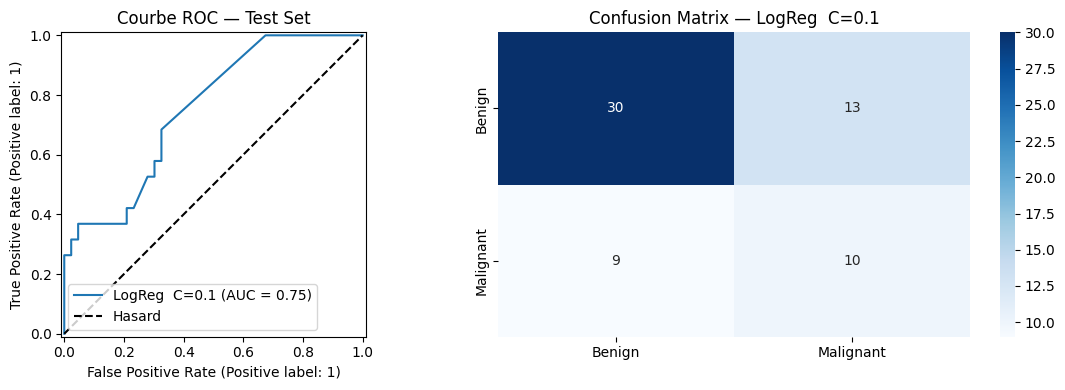

Classifieur sauvegardé : /content/drive/MyDrive/PFA/models/effnet_classifier.pkl


In [55]:
import time
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import RocCurveDisplay

# ── Extracteur : EfficientNet-B3 sans tête de classification ─────────────────
feat_extractor = timm.create_model('efficientnet_b3', pretrained=True, num_classes=0)
feat_extractor = feat_extractor.to(DEVICE).eval()
print(f'Extracteur chargé — sortie : 1536 features/image')

FEAT_TF = T.Compose([
    T.Resize((300, 300)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

def extract_features(df_crops):
    """Extrait les features depuis des crops GT (CropDataset)."""
    ds     = CropDataset(df_crops, FEAT_TF)
    loader = DataLoader(ds, batch_size=16, shuffle=False, num_workers=2)
    feats, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            f = feat_extractor(x.to(DEVICE)).cpu().numpy()
            feats.append(f); labels.extend(y.numpy())
    return np.vstack(feats), np.array(labels)

print('Extraction features depuis crops GT (PAD=3.0)...')
t0_feat = time.time()
print('  Train...'); X_tr,  y_tr  = extract_features(train_df)
print('  Val...');   X_val, y_val = extract_features(val_df)
print('  Test...');  X_te,  y_te  = extract_features(test_df)
t1_feat = time.time()
print(f'Feature dim : {X_tr.shape[1]} | Train:{len(y_tr)} Val:{len(y_val)} Test:{len(y_te)}')
print(f'Temps extraction features : {t1_feat-t0_feat:.1f}s')

# Combiner train + val → plus de données pour l'entraînement final
X_tv = np.vstack([X_tr, X_val])
y_tv = np.concatenate([y_tr, y_val])

# ── Normalisation ─────────────────────────────────────────────────────────────
scaler  = StandardScaler()
X_tv_s  = scaler.fit_transform(X_tv)
X_te_s  = scaler.transform(X_te)

# ── SMOTE : rééquilibrage par oversampling synthétique ────────────────────────
print(f'\nDistribution avant SMOTE : {dict(Counter(y_tv))}')
k_smote = min(5, min(Counter(y_tv).values()) - 1)
smote   = SMOTE(random_state=42, k_neighbors=max(1, k_smote))
X_tv_sm, y_tv_sm = smote.fit_resample(X_tv_s, y_tv)
print(f'Distribution après SMOTE : {dict(Counter(y_tv_sm))}')
print(f'Échantillons synthétiques ajoutés : {len(y_tv_sm) - len(y_tv)}')

# ── Validation croisée 5-fold sur données SMOTE ───────────────────────────────
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = {
    'LogReg  C=1  ':  LogisticRegression(C=1,   class_weight='balanced', max_iter=1000, random_state=42),
    'LogReg  C=0.1':  LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, random_state=42),
    'SVM RBF C=1  ':  SVC(C=1,  kernel='rbf', class_weight='balanced', probability=True, random_state=42),
    'SVM RBF C=10 ':  SVC(C=10, kernel='rbf', class_weight='balanced', probability=True, random_state=42),
}

print('\n=== Validation croisée 5-fold (train+val + SMOTE) ===')
best_name, best_cv, best_clf = None, 0, None
for name, clf in candidates.items():
    scores = cross_val_score(clf, X_tv_sm, y_tv_sm, cv=skf, scoring='roc_auc', n_jobs=-1)
    print(f'  {name} : AUC = {scores.mean():.3f} ± {scores.std():.3f}')
    if scores.mean() > best_cv:
        best_cv, best_name, best_clf = scores.mean(), name, clf

print(f'\nMeilleur : {best_name.strip()} (CV AUC = {best_cv:.3f})')

# ── Entraînement final sur données SMOTE ─────────────────────────────────────
t0_train = time.time()
best_clf.fit(X_tv_sm, y_tv_sm)
t1_train = time.time()
print(f'Temps entraînement SVM : {t1_train-t0_train:.2f}s')

# ── Évaluation sur test (données réelles, sans SMOTE) ────────────────────────
t0_inf = time.time()
te_preds  = best_clf.predict(X_te_s)
te_probs  = best_clf.predict_proba(X_te_s)[:,1]
t1_inf = time.time()
te_auc    = roc_auc_score(y_te, te_probs)
te_f1     = f1_score(y_te, te_preds)

print(f'\n=== Évaluation Quantitative — Test Set ({len(y_te)} images) ===')
print(f'Execution Time inférence : {t1_inf-t0_inf:.3f}s  '
      f'({(t1_inf-t0_inf)/len(y_te)*1000:.1f}ms/image)')
print(f'AUC      : {te_auc:.4f}')
print(f'F1-Score : {te_f1:.4f}')
print(classification_report(y_te, te_preds, target_names=['Benign','Malignant']))

# Courbe ROC + Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_te, te_probs,
    name=best_name.strip(), ax=axes[0])
axes[0].plot([0,1],[0,1],'k--',label='Hasard')
axes[0].set_title('Courbe ROC — Test Set'); axes[0].legend()
cm = confusion_matrix(y_te, te_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign','Malignant'],
            yticklabels=['Benign','Malignant'])
axes[1].set_title(f'Confusion Matrix — {best_name.strip()}')
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'effnet_feat_extraction.png'), dpi=150, bbox_inches='tight')
plt.show()

# Sauvegarder le classifieur
import joblib
joblib.dump({'clf': best_clf, 'scaler': scaler},
           os.path.join(MODELS_DIR, 'effnet_classifier.pkl'))
print(f'Classifieur sauvegardé : {MODELS_DIR}/effnet_classifier.pkl')


## Optimisation du seuil de décision

Par défaut `threshold = 0.5` n'est pas optimal pour un dataset déséquilibré.

On cherche le seuil qui maximise les performances selon 2 critères :
- **Youden Index** (équilibre général)
- **Seuil clinique** (favorise le recall malin — ne pas manquer de cancers)


Seuil Youden optimal : 0.338

── Seuil Youden ──
              precision    recall  f1-score   support

      Benign       0.83      0.67      0.74        43
   Malignant       0.48      0.68      0.57        19

    accuracy                           0.68        62
   macro avg       0.66      0.68      0.65        62
weighted avg       0.72      0.68      0.69        62

── Seuil clinique (0.35) ──
              precision    recall  f1-score   support

      Benign       0.78      0.67      0.72        43
   Malignant       0.44      0.58      0.50        19

    accuracy                           0.65        62
   macro avg       0.61      0.63      0.61        62
weighted avg       0.68      0.65      0.66        62

=== Comparaison seuils ===
     Seuil      Acc      AUC  Rec.Malin  Prec.Malin
     Défaut (0.50)    0.645    0.750      0.526       0.435
     Youden (0.34)    0.677    0.750      0.684       0.481
   Clinique (0.35)    0.645    0.750      0.579       0.440


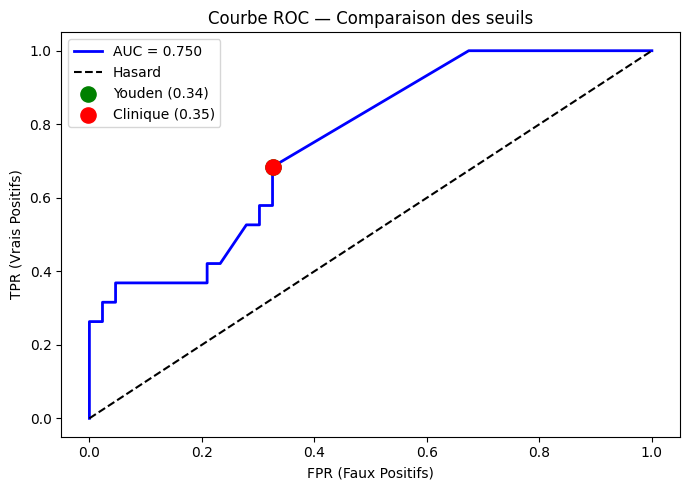

In [56]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_te, te_probs)

# ── Seuil optimal Youden (maximise TPR - FPR) ────────────────────────────────
youden_idx = np.argmax(tpr - fpr)
best_thr   = thresholds[youden_idx]
print(f'Seuil Youden optimal : {best_thr:.3f}')

te_preds_youden = (te_probs >= best_thr).astype(int)
print('\n── Seuil Youden ──')
print(classification_report(y_te, te_preds_youden, target_names=['Benign','Malignant']))

# ── Seuil clinique : favoriser recall malin (ne pas manquer de cancers) ───────
clin_thr = 0.35
te_preds_clin = (te_probs >= clin_thr).astype(int)
print(f'── Seuil clinique ({clin_thr}) ──')
print(classification_report(y_te, te_preds_clin, target_names=['Benign','Malignant']))

# ── Tableau comparatif des 3 seuils ──────────────────────────────────────────
print('=== Comparaison seuils ===')
print(f'{"Seuil":>10s} {"Acc":>8s} {"AUC":>8s} {"Rec.Malin":>10s} {"Prec.Malin":>11s}')
for thr, preds, label in [
    (0.50,      te_preds,        'Défaut (0.50)'),
    (best_thr,  te_preds_youden, f'Youden ({best_thr:.2f})'),
    (clin_thr,  te_preds_clin,   f'Clinique ({clin_thr})'),
]:
    from sklearn.metrics import recall_score, precision_score
    acc  = accuracy_score(y_te, preds)
    rec  = recall_score(y_te, preds)
    prec = precision_score(y_te, preds, zero_division=0)
    print(f'{label:>18s} {acc:>8.3f} {te_auc:>8.3f} {rec:>10.3f} {prec:>11.3f}')

# ── Courbe ROC avec les 3 seuils marqués ─────────────────────────────────────
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, 'b-', lw=2, label=f'AUC = {te_auc:.3f}')
plt.plot([0,1],[0,1],'k--', label='Hasard')
plt.scatter(fpr[youden_idx], tpr[youden_idx], s=120,
            color='green', zorder=5, label=f'Youden ({best_thr:.2f})')
clin_idx = np.argmin(np.abs(thresholds - clin_thr))
plt.scatter(fpr[clin_idx], tpr[clin_idx], s=120,
            color='red', zorder=5, label=f'Clinique ({clin_thr})')
plt.xlabel('FPR (Faux Positifs)'); plt.ylabel('TPR (Vrais Positifs)')
plt.title('Courbe ROC — Comparaison des seuils')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'roc_thresholds.png'), dpi=150)
plt.show()


## Partie 3 — Fine-Tuning U-Net

**Corrections appliquées vs tentative précédente :**
- `build_seg_records` filtre automatiquement les masques vides
- Loss : **Focal + Dice** (remplace BCE + Dice) → robuste aux masques vides
- `Focal loss` : pénalise davantage les pixels mal classés, ignore les faciles

**Objectif** : segmenter la lésion (masque binaire) à partir de l'image complète.

**Masque GT** : cercle généré depuis `(cx, cy, radius)` du metadata.

**Défi** : les lésions occupent ~3% des pixels → déséquilibre foreground/background.
**Solution** : `pos_weight` dynamique dans la loss pour forcer le modèle à détecter les pixels positifs.


=== Chargement SegDataset ===
Train :
  Depuis fichier masque : 184
  Depuis coords (COORD_SX=0.109, SY=0.014) : 7
  Masques vides ignorés : 1
Val   :
  Depuis fichier masque : 41
  Depuis coords (COORD_SX=0.109, SY=0.014) : 0
Test  :
  Depuis fichier masque : 41
  Depuis coords (COORD_SX=0.109, SY=0.014) : 1

SegDataset — Train:190 Val:41 Test:42


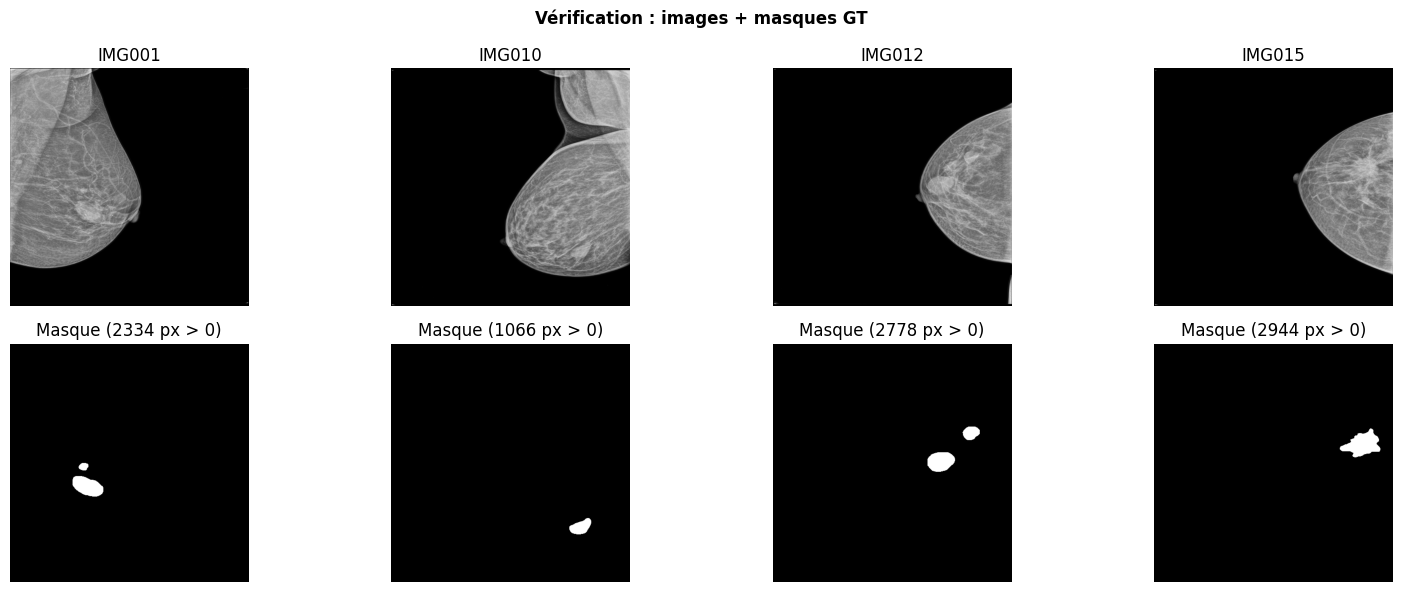

In [57]:
SEG_TF = T.Compose([
    T.Resize((SEG_SIZE, SEG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

# ── Stratégie 1 : masques depuis fichiers (MASK_DIR)
# ── Stratégie 2 : cercles depuis coordonnées (avec mise à l'échelle auto)
def build_seg_records(df, skip_empty=True):
    records = []
    n_skipped = 0; n_from_file = 0; n_from_coords = 0
    for ref, grp in df.groupby('ref'):
        path = get_img_path(ref)
        if path is None: continue
        img = Image.open(path); W, H = img.size
        lesions = [(r['cx'],r['cy'],r['radius']) for _,r in grp.iterrows()]

        # ── Stratégie 1 : charger masque depuis fichier ───────────────────────
        mask_bool = load_mask_file(ref, W, H)
        if mask_bool is not None:
            mask = (mask_bool * 255).astype(np.uint8)
            n_from_file += 1
        else:
            # ── Stratégie 2 : générer cercle depuis coordonnées (scalées) ─────
            mask = np.zeros((H, W), dtype=np.uint8)
            for cx, cy, r in lesions:
                mask |= gt_circle_mask(W, H, int(cx), int(cy), int(r),
                                       sx=COORD_SX, sy=COORD_SY).astype(np.uint8) * 255
            n_from_coords += 1

        if skip_empty and mask.sum() == 0:
            n_skipped += 1; continue
        records.append({'ref': ref, 'path': path, 'lesions': lesions,
                        'mask_cache': mask})
    print(f'  Depuis fichier masque : {n_from_file}')
    print(f'  Depuis coords (COORD_SX={COORD_SX:.3f}, SY={COORD_SY:.3f}) : {n_from_coords}')
    if n_skipped: print(f'  Masques vides ignorés : {n_skipped}')
    return records

class SegDataset(Dataset):
    def __init__(self, df, augment=False):
        self.recs = build_seg_records(df)
        self.aug  = augment
    def __len__(self): return len(self.recs)
    def __getitem__(self, idx):
        rec  = self.recs[idx]
        img  = Image.open(rec['path']).convert('RGB')
        mask = rec['mask_cache'].copy()
        if self.aug:
            if random.random() > 0.5:
                img  = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask[:, ::-1].copy()
            if random.random() > 0.5:
                img  = img.transpose(Image.FLIP_TOP_BOTTOM)
                mask = mask[::-1, :].copy()
        img_t  = SEG_TF(img)
        mask_t = torch.from_numpy(
            np.array(Image.fromarray(mask).resize(
                (SEG_SIZE, SEG_SIZE), Image.NEAREST)) / 255.0
        ).float().unsqueeze(0)
        return img_t, mask_t

print('=== Chargement SegDataset ===')
print('Train :'); recs_tr = build_seg_records(train_df)
print('Val   :'); recs_va = build_seg_records(val_df)
print('Test  :'); recs_te = build_seg_records(test_df)
print(f'\nSegDataset — Train:{len(recs_tr)} Val:{len(recs_va)} Test:{len(recs_te)}')

if max(len(recs_tr), len(recs_va), len(recs_te)) == 0:
    print('\n❌ TOUS LES MASQUES SONT VIDES. Vérifier :')
    print('   1. Le chemin MASK_DIR contient-il des fichiers PNG ?')
    print(f'      {MASK_DIR}')
    print('   2. Les coordonnées cx/cy/radius sont-elles dans la bonne unité ?')
    print(f'      cx_max={df_bm["cx"].max():.0f}  '
          f'cy_max={df_bm["cy"].max():.0f}  '
          f'radius_max={df_bm["radius"].max():.0f}')
    print('   3. Essayer de modifier COORD_SX / COORD_SY manuellement.')
else:
    # ── Diagnostic visuel : 4 exemples image + masque ────────────────────────
    n_show = min(4, len(recs_tr))
    fig, axes = plt.subplots(2, n_show, figsize=(4*n_show, 6))
    if n_show == 1: axes = axes[:, np.newaxis]
    for i, rec in enumerate(recs_tr[:n_show]):
        img  = Image.open(rec['path']).convert('RGB')
        mask = rec['mask_cache']
        axes[0][i].imshow(img)
        axes[0][i].set_title(f'{rec["ref"]}'); axes[0][i].axis('off')
        axes[1][i].imshow(mask, cmap='gray')
        px = mask.sum() // 255
        axes[1][i].set_title(f'Masque ({px} px > 0)')
        axes[1][i].axis('off')
    plt.suptitle('Vérification : images + masques GT',
                 fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()


In [58]:
train_seg = DataLoader(SegDataset(train_df,True),  SEG_BATCH, shuffle=True,  num_workers=2)
val_seg   = DataLoader(SegDataset(val_df,  False), SEG_BATCH, shuffle=False, num_workers=2)
test_seg  = DataLoader(SegDataset(test_df, False), SEG_BATCH, shuffle=False, num_workers=2)

unet = smp.Unet('resnet34', encoder_weights='imagenet',
                in_channels=3, classes=1, activation=None).to(DEVICE)
opt_seg   = torch.optim.AdamW(unet.parameters(), lr=SEG_LR, weight_decay=1e-4)
sched_seg = torch.optim.lr_scheduler.CosineAnnealingLR(opt_seg, SEG_EPOCHS)

def dice_loss(pred, tgt, smooth=1.):
    p = torch.sigmoid(pred)
    i = (p*tgt).sum((2,3))
    u = p.sum((2,3)) + tgt.sum((2,3))
    return 1 - (2*i + smooth) / (u + smooth)

def focal_loss(pred, tgt, gamma=2., alpha=0.75):
    bce = F.binary_cross_entropy_with_logits(pred, tgt, reduction='none')
    pt  = torch.exp(-bce)
    return (alpha * (1-pt)**gamma * bce).mean()

def seg_loss(pred, tgt):
    # Focal loss (robuste aux masques vides) + Dice loss
    return focal_loss(pred, tgt) + dice_loss(pred, tgt).mean()

# Vérification
n_empty_tr = sum(1 for _,y in train_seg if y.sum()==0)
n_empty_va = sum(1 for _,y in val_seg   if y.sum()==0)
print(f'Masques vides train : {n_empty_tr}/{len(train_seg.dataset)}')
print(f'Masques vides val   : {n_empty_va}/{len(val_seg.dataset)}')

import time as _time

@torch.no_grad()
def dice_score(pred, gt, thr=0.5):
    pb = (torch.sigmoid(pred) > thr).float()
    i  = (pb * gt).sum().item()
    d  = pb.sum().item() + gt.sum().item()
    return 2 * i / (d + 1e-8)

best_dice_val = 0.; pat_seg = 0
hist_seg = {'loss': [], 'dice': []}

for ep in range(1, SEG_EPOCHS+1):
    unet.train(); tloss = 0.
    for x, y in train_seg:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt_seg.zero_grad()
        l = seg_loss(unet(x), y); l.backward(); opt_seg.step()
        tloss += l.item() * x.size(0)
    unet.eval(); dices = []
    with torch.no_grad():
        for x, y in val_seg:
            x, y = x.to(DEVICE), y.to(DEVICE)
            for p, m in zip(unet(x), y):
                dices.append(dice_score(p.unsqueeze(0), m.unsqueeze(0)))
    tl = tloss / len(train_seg.dataset)
    vd = np.mean(dices)
    sched_seg.step()
    hist_seg['loss'].append(tl); hist_seg['dice'].append(vd)
    print(f'Ep {ep:3d}/{SEG_EPOCHS} | Loss {tl:.4f} | Val Dice {vd:.3f}', end='')
    if vd > best_dice_val:
        best_dice_val = vd; pat_seg = 0
        torch.save(unet.state_dict(), os.path.join(MODELS_DIR,'unet_mammo.pt'))
        print(' ✓ saved', end='')
    else:
        pat_seg += 1
        if pat_seg >= SEG_PATIENCE: print(f'\nEarly stop ep {ep}'); break
    print()
print(f'\nMeilleur Val Dice : {best_dice_val:.4f}')


  Depuis fichier masque : 184
  Depuis coords (COORD_SX=0.109, SY=0.014) : 7
  Masques vides ignorés : 1
  Depuis fichier masque : 41
  Depuis coords (COORD_SX=0.109, SY=0.014) : 0
  Depuis fichier masque : 41
  Depuis coords (COORD_SX=0.109, SY=0.014) : 1
Masques vides train : 0/190
Masques vides val   : 0/41
Ep   1/30 | Loss 1.2813 | Val Dice 0.027 ✓ saved
Ep   2/30 | Loss 1.1395 | Val Dice 0.054 ✓ saved
Ep   3/30 | Loss 1.1136 | Val Dice 0.112 ✓ saved
Ep   4/30 | Loss 1.0812 | Val Dice 0.167 ✓ saved
Ep   5/30 | Loss 1.0578 | Val Dice 0.222 ✓ saved
Ep   6/30 | Loss 1.0303 | Val Dice 0.298 ✓ saved
Ep   7/30 | Loss 1.0149 | Val Dice 0.298 ✓ saved
Ep   8/30 | Loss 1.0085 | Val Dice 0.358 ✓ saved
Ep   9/30 | Loss 1.0000 | Val Dice 0.372 ✓ saved
Ep  10/30 | Loss 0.9883 | Val Dice 0.424 ✓ saved
Ep  11/30 | Loss 0.9855 | Val Dice 0.443 ✓ saved
Ep  12/30 | Loss 0.9806 | Val Dice 0.454 ✓ saved
Ep  13/30 | Loss 0.9772 | Val Dice 0.436
Ep  14/30 | Loss 0.9728 | Val Dice 0.415
Ep  15/30 | Loss 0

=== Évaluation Quantitative U-Net — Test Set ===
Execution Time : 0.78s  (18.7ms/image)
Dice moy : 0.4658 ± 0.2877
% Dice>0.7 : 23.8%
% Dice>0.9 : 0.0%


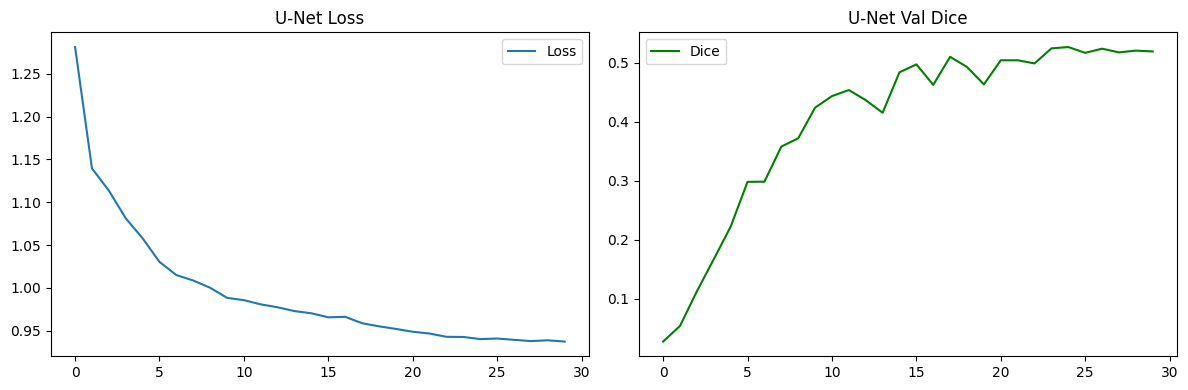

In [59]:
unet_path = os.path.join(MODELS_DIR,'unet_mammo.pt')
if not os.path.exists(unet_path):
    print('ATTENTION : U-Net jamais sauvegardé (Dice=0 tout au long).')
    print('Causes possibles :')
    print('  1. Coordonnées (cx,cy,radius) hors de la résolution des images')
    print('  2. Val set contient uniquement des masques vides')
    print('  3. Le modèle a besoin de plus depochs')
    raise SystemExit('U-Net non entraîné — voir diagnostic ci-dessus.')
unet.load_state_dict(torch.load(unet_path, map_location=DEVICE))
unet.eval()
dices = []
t0_unet = _time.time()
with torch.no_grad():
    for x, y in test_seg:
        x, y = x.to(DEVICE), y.to(DEVICE)
        for p, m in zip(unet(x), y):
            dices.append(dice_score(p.unsqueeze(0), m.unsqueeze(0)))
t1_unet = _time.time()
n_test_unet = len(test_seg.dataset)

print('=== Évaluation Quantitative U-Net — Test Set ===')
print(f'Execution Time : {t1_unet-t0_unet:.2f}s  '
      f'({(t1_unet-t0_unet)/n_test_unet*1000:.1f}ms/image)')
print(f'Dice moy : {np.mean(dices):.4f} ± {np.std(dices):.4f}')
print(f'% Dice>0.7 : {(np.array(dices)>0.7).mean()*100:.1f}%')
print(f'% Dice>0.9 : {(np.array(dices)>0.9).mean()*100:.1f}%')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_seg['loss'], label='Loss'); ax1.legend(); ax1.set_title('U-Net Loss')
ax2.plot(hist_seg['dice'], label='Dice', color='green')
ax2.legend(); ax2.set_title('U-Net Val Dice')
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'unet_results.png'), dpi=150, bbox_inches='tight')
plt.show()


In [60]:
from transformers import SamModel, SamProcessor

# Charger le vrai SAM original (facebook/sam-vit-base)
# C'est la baseline zero-shot ET le point de départ de notre fine-tuning.
print(f'Chargement SAM original : {SAM_BASE_ID}')
sam_proc  = SamProcessor.from_pretrained(SAM_BASE_ID)
sam_model = SamModel.from_pretrained(SAM_BASE_ID).to(DEVICE).eval()
print(f'SAM original charge ({SAM_BASE_ID})')
print(f'Params : {sum(p.numel() for p in sam_model.parameters()):,}')


Chargement SAM original : facebook/sam-vit-base


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

SAM original charge (facebook/sam-vit-base)
Params : 93,735,728


In [61]:
MIN_SAM_IOU = 0.20
MIN_CROP_PX = 64

def _hotspot(img_pil):
    W,H=img_pil.size; SC=8
    sw,sh=max(1,W//SC),max(1,H//SC)
    small=np.array(img_pil.convert('L').resize((sw,sh),Image.LANCZOS),dtype=np.float32)
    k=min(7,sw-1,sh-1)
    if k<2: return W//2,H//2
    wins=sliding_window_view(small,(k,k))
    vmap=wins.var((-2,-1)); mmap=wins.mean((-2,-1))
    sh_,sw_=vmap.shape
    breast=small[:sh_,:sw_]>small.max()*0.08
    score=0.6*(vmap/(vmap.max()+1e-8))+0.4*(mmap/(mmap.max()+1e-8))
    score[~breast]=-1
    vy,vx=np.unravel_index(score.argmax(),score.shape)
    return min(int((vx+k//2)*SC),W-1), min(int((vy+k//2)*SC),H-1)

def sam_run(img_pil):
    W,H=img_pil.size
    cx,cy=_hotspot(img_pil)
    off=min(W,H)//8
    pts=[[cx,cy],[max(0,cx-off),cy],[min(W-1,cx+off),cy],
         [cx,max(0,cy-off)],[cx,min(H-1,cy+off)]]
    inp=sam_proc(images=img_pil,input_points=[[pts]],return_tensors='pt').to(DEVICE)
    with torch.no_grad(): out=sam_model(**inp)
    raw=out.pred_masks.squeeze()
    sc =(out.iou_scores.squeeze().cpu().numpy().flatten()
         if out.iou_scores is not None else np.array([1.]))
    if raw.ndim==2: raw=raw.unsqueeze(0)
    masks=(raw.cpu().numpy()>0.5)
    best,bsc=-1,-1
    for i,(m,s) in enumerate(zip(masks,sc)):
        adj=float(s)*(1-m.mean())
        if adj>bsc and float(s)>MIN_SAM_IOU: bsc=adj; best=i
    if best<0: best=0
    mask=masks[best]
    rows=np.where(mask.any(1))[0]; cols=np.where(mask.any(0))[0]
    if len(rows)==0 or bsc<0:
        h=max(int(min(W,H)*0.15),MIN_CROP_PX)
        return mask, bsc, (max(0,cx-h),max(0,cy-h),min(W,cx+h),min(H,cy+h))
    return mask, bsc, (int(cols[0]),int(rows[0]),int(cols[-1]),int(rows[-1]))

print('Fonctions SAM prêtes.')


Fonctions SAM prêtes.


  Depuis fichier masque : 41
  Depuis coords (COORD_SX=0.109, SY=0.014) : 1
Evaluation SAM sur 42 images test...
  10/42 — Dice moy: 0.034
  20/42 — Dice moy: 0.057
  30/42 — Dice moy: 0.090
  40/42 — Dice moy: 0.093

=== Évaluation Quantitative SAM — Test Set ===
Execution Time : 21.91s  (521.6ms/image)
Dice moy   : 0.0906 ± 0.1416
% Dice>0.7 : 2.4%
Fallback   : 0/42


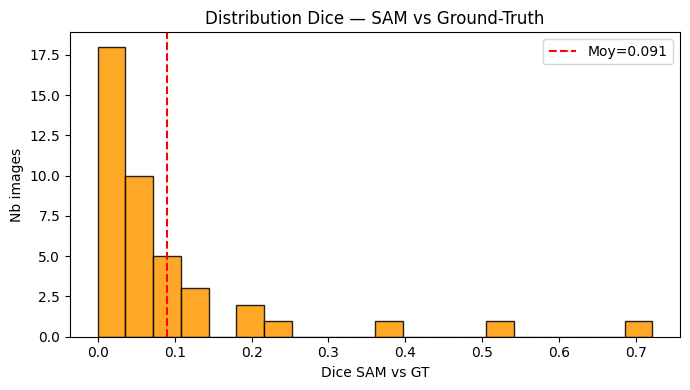

In [62]:
# test_recs contient déjà 'mask_cache' (les vrais masques GT chargés depuis
# les fichiers PNG — identiques à ceux utilisés pour entraîner U-Net)
# On utilise ces masques comme GT pour SAM, pas des cercles recalculés.
test_recs = build_seg_records(test_df)
sam_dices = []
n_fallback = 0

print(f'Evaluation SAM sur {len(test_recs)} images test...')
t0_sam = _time.time()
for i, rec in enumerate(test_recs):
    img = Image.open(rec['path']).convert('RGB')
    W, H = img.size
    gt = (rec['mask_cache'] > 0)
    sam_mask, score, _ = sam_run(img)
    if sam_mask.shape != (H, W):
        sam_mask = np.array(
            Image.fromarray(sam_mask.astype(np.uint8) * 255)
            .resize((W, H), Image.NEAREST)) > 127
    inter = (sam_mask & gt).sum()
    dice  = 2 * inter / (sam_mask.sum() + gt.sum() + 1e-8)
    sam_dices.append(dice)
    if score < MIN_SAM_IOU: n_fallback += 1
    if (i+1) % 10 == 0:
        print(f'  {i+1}/{len(test_recs)} — Dice moy: {np.mean(sam_dices):.3f}')
t1_sam = _time.time()

print(f'\n=== Évaluation Quantitative SAM — Test Set ===')
print(f'Execution Time : {t1_sam-t0_sam:.2f}s  '
      f'({(t1_sam-t0_sam)/len(test_recs)*1000:.1f}ms/image)')
print(f'Dice moy   : {np.mean(sam_dices):.4f} ± {np.std(sam_dices):.4f}')
print(f'% Dice>0.7 : {(np.array(sam_dices)>0.7).mean()*100:.1f}%')
print(f'Fallback   : {n_fallback}/{len(test_recs)}')

plt.figure(figsize=(7,4))
plt.hist(sam_dices, bins=20, color='#FF9800', edgecolor='black', alpha=0.85)
plt.axvline(np.mean(sam_dices), color='red', linestyle='--',
            label=f'Moy={np.mean(sam_dices):.3f}')
plt.xlabel('Dice SAM vs GT'); plt.ylabel('Nb images')
plt.title('Distribution Dice — SAM vs Ground-Truth')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'sam_dice.png'), dpi=150)
plt.show()


## SAM Fine-Tuning sur DMID

SAM a 3 composants. On gèle tout sauf le **Mask Decoder** :

```
Image → [Vision Encoder ViT  — GELÉ  ~87M params] → embeddings
Prompt → [Prompt Encoder     — GELÉ  ~6M params]  → prompt tokens
         [Mask Decoder       — ENTRAÎNÉ ~4M params] → masque
```

**Pendant l'entraînement** : on fournit le centre GT de la lésion comme prompt
(point foreground = `cx*COORD_SX, cy*COORD_SY`).

**Pendant l'évaluation** : on utilise le hotspot automatique (variance image)
— pas de GT, comme en conditions réelles.

| | SAM original | SAM fine-tuné | U-Net fine-tuné |
|---|---|---|---|
| Entraînement domaine | Non | ✓ DMID | ✓ DMID |
| Params entraînés | 0 | ~4M | ~25M |
| Prompt requis | Hotspot | Hotspot | Aucun |


SAM params total     : 93,735,728
SAM params entraines : 4,058,340 (Mask Decoder seulement)
SAM params geles     : 89,677,388
Ep   1/20 | Loss 1.1007 | Val IoU 0.000 saved
Ep   2/20 | Loss 0.9884 | Val IoU 0.000 saved
Ep   3/20 | Loss 0.9771 | Val IoU 0.000 saved
Ep   4/20 | Loss 0.9658 | Val IoU 0.000 saved
Ep   5/20 | Loss 0.9457 | Val IoU 0.057 saved
Ep   6/20 | Loss 0.8558 | Val IoU 0.196 saved
Ep   7/20 | Loss 0.8153 | Val IoU 0.226 saved
Ep   8/20 | Loss 0.7285 | Val IoU 0.261 saved
Ep   9/20 | Loss 0.6857 | Val IoU 0.283 saved
Ep  10/20 | Loss 0.6524 | Val IoU 0.278
Ep  11/20 | Loss 0.6326 | Val IoU 0.288 saved
Ep  12/20 | Loss 0.6057 | Val IoU 0.299 saved
Ep  13/20 | Loss 0.5863 | Val IoU 0.303 saved
Ep  14/20 | Loss 0.5729 | Val IoU 0.310 saved
Ep  15/20 | Loss 0.5634 | Val IoU 0.309
Ep  16/20 | Loss 0.5585 | Val IoU 0.306
Ep  17/20 | Loss 0.5551 | Val IoU 0.297
Ep  18/20 | Loss 0.5517 | Val IoU 0.301
Ep  19/20 | Loss 0.5472 | Val IoU 0.305
Early stop ep 19

Meilleur Val IoU S

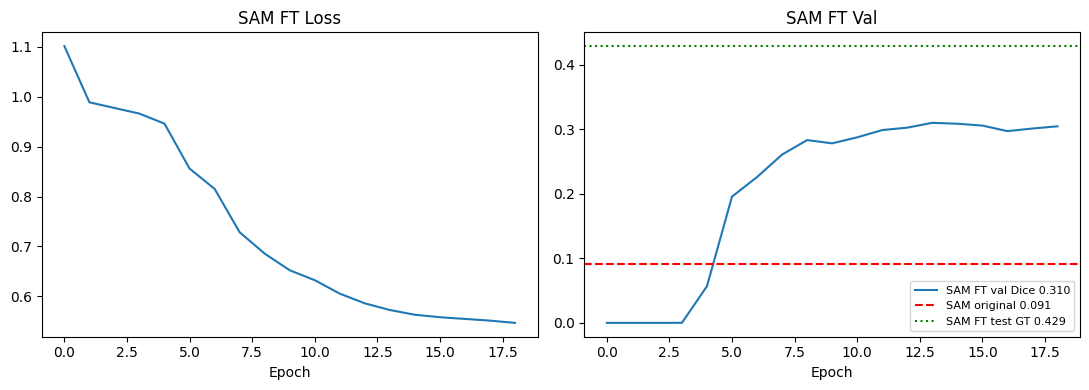

In [63]:
SAM_FT_LR      = 1e-5
SAM_FT_EPOCHS  = 20
SAM_FT_PATIENCE = 5
SAM_FT_ACCUM    = 4   # gradient accumulation (=batch virtuel de 4 images)

# ── Geler Vision Encoder + Prompt Encoder ─────────────────────────────────────
for p in sam_model.vision_encoder.parameters(): p.requires_grad = False
for p in sam_model.prompt_encoder.parameters(): p.requires_grad = False
for p in sam_model.mask_decoder.parameters():  p.requires_grad = True

total_p = sum(p.numel() for p in sam_model.parameters())
train_p = sum(p.numel() for p in sam_model.parameters() if p.requires_grad)
print(f'SAM params total     : {total_p:,}')
print(f'SAM params entraines : {train_p:,} (Mask Decoder seulement)')
print(f'SAM params geles     : {total_p-train_p:,}')

sam_ft_opt   = torch.optim.AdamW(
    [p for p in sam_model.parameters() if p.requires_grad],
    lr=SAM_FT_LR, weight_decay=1e-4)
sam_ft_sched = torch.optim.lr_scheduler.CosineAnnealingLR(sam_ft_opt, SAM_FT_EPOCHS)

def _sam_forward(rec, compute_grad=True):
    """
    Passe avant SAM sur un enregistrement seg.
    Prompt = centroïde des lésions GT (scalé).
    Retourne (loss, iou_sur_sortie_SAM).
    """
    img = Image.open(rec['path']).convert('RGB')
    W, H = img.size
    gt   = rec['mask_cache']  # (H,W) uint8

    # Centroïde de toutes les lésions de l'image
    pts_scaled = [(max(0,min(W-1,int(cx*COORD_SX))),
                   max(0,min(H-1,int(cy*COORD_SY))))
                  for cx,cy,r in rec['lesions']]
    cx_s = int(np.mean([p[0] for p in pts_scaled]))
    cy_s = int(np.mean([p[1] for p in pts_scaled]))

    inputs = sam_proc(images=img,
                      input_points=[[[cx_s, cy_s]]],
                      input_labels=[[1]],
                      return_tensors='pt')
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    ctx = torch.enable_grad() if compute_grad else torch.no_grad()
    with ctx:
        out = sam_model(**inputs, multimask_output=False)
        # pred_masks shape : (batch, num_prompts, num_masks, H, W)
        # On prend batch=0, prompt_set=0, mask=0 → (H, W)
        pred = out.pred_masks[0, 0, 0]      # (pH, pW)
        pH, pW = pred.shape

        # GT redimensionné au format de sortie SAM : (pH, pW)
        gt_t = torch.from_numpy(
            np.array(Image.fromarray(gt).resize((pW, pH), Image.NEAREST)) / 255.0
        ).float().to(DEVICE)                # (pH, pW)

        # Ajouter dims batch+canal pour focal_loss / dice_loss : (1,1,pH,pW)
        pred_4d = pred.unsqueeze(0).unsqueeze(0)
        gt_4d   = gt_t.unsqueeze(0).unsqueeze(0)

        loss = focal_loss(pred_4d, gt_4d) + dice_loss(pred_4d, gt_4d).mean()

        pb  = (torch.sigmoid(pred) > 0.5).float()  # (pH, pW)
        i   = (pb * gt_t).sum().item()
        u   = (pb + gt_t).clamp(0, 1).sum().item()
        iou = i / (u + 1e-8)

    return loss, iou

# ── Boucle d'entraînement ──────────────────────────────────────────────────────
best_sam_iou = 0.; pat_sam = 0
hist_sam = {'loss': [], 'iou': []}

for ep in range(1, SAM_FT_EPOCHS+1):
    sam_model.train()
    sam_model.vision_encoder.eval()   # ViT gelé → toujours en mode eval
    sam_model.prompt_encoder.eval()

    tloss = 0.; sam_ft_opt.zero_grad()
    for j, rec in enumerate(recs_tr):
        loss, _ = _sam_forward(rec, compute_grad=True)
        (loss / SAM_FT_ACCUM).backward()
        tloss += loss.item()
        if (j+1) % SAM_FT_ACCUM == 0 or (j+1) == len(recs_tr):
            sam_ft_opt.step(); sam_ft_opt.zero_grad()

    sam_model.eval()
    val_ious_ft = [_sam_forward(rec, compute_grad=False)[1] for rec in recs_va]
    vi = float(np.mean(val_ious_ft))
    tl = tloss / len(recs_tr)
    sam_ft_sched.step()
    hist_sam['loss'].append(tl); hist_sam['iou'].append(vi)

    print(f'Ep {ep:3d}/{SAM_FT_EPOCHS} | Loss {tl:.4f} | Val IoU {vi:.3f}', end='')
    if vi > best_sam_iou:
        best_sam_iou = vi; pat_sam = 0
        torch.save(sam_model.state_dict(),
                   os.path.join(MODELS_DIR,'sam_finetuned.pt'))
        print(' saved', end='')
    else:
        pat_sam += 1
        if pat_sam >= SAM_FT_PATIENCE:
            print(f'\nEarly stop ep {ep}'); break
    print()
print(f'\nMeilleur Val IoU SAM fine-tune : {best_sam_iou:.4f}')

# ── Charger meilleur checkpoint ───────────────────────────────────────────────
sam_model.load_state_dict(
    torch.load(os.path.join(MODELS_DIR,'sam_finetuned.pt'), map_location=DEVICE))
sam_model.eval()

# ── Évaluation 1 : prompt GT centroïde ───────────────────────────────────────
sam_ft_dices_gt = []
t0_ft_gt = _time.time()
for rec in recs_te:
    img = Image.open(rec['path']).convert('RGB')
    W, H = img.size
    gt   = rec['mask_cache'] > 0
    pts_s = [(max(0,min(W-1,int(cx*COORD_SX))),
              max(0,min(H-1,int(cy*COORD_SY))))
             for cx,cy,r in rec['lesions']]
    cx_s = int(np.mean([p[0] for p in pts_s]))
    cy_s = int(np.mean([p[1] for p in pts_s]))
    inputs = sam_proc(images=img, input_points=[[[cx_s, cy_s]]],
                      input_labels=[[1]], return_tensors='pt')
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        out = sam_model(**inputs, multimask_output=False)
        pred = out.pred_masks[0, 0, 0]
    sam_mask = (torch.sigmoid(pred) > 0.5).cpu().numpy()
    if sam_mask.shape != (H, W):
        sam_mask = np.array(
            Image.fromarray(sam_mask.astype(np.uint8)*255)
            .resize((W, H), Image.NEAREST)) > 127
    inter = (sam_mask & gt).sum()
    sam_ft_dices_gt.append(2*inter/(sam_mask.sum()+gt.sum()+1e-8))
t1_ft_gt = _time.time()

# ── Évaluation 2 : hotspot automatique ────────────────────────────────────────
sam_ft_dices_hs = []
t0_ft_hs = _time.time()
for rec in recs_te:
    img = Image.open(rec['path']).convert('RGB')
    W, H = img.size
    gt   = rec['mask_cache'] > 0
    cx_h, cy_h = _hotspot(img)
    inputs = sam_proc(images=img, input_points=[[[cx_h, cy_h]]],
                      input_labels=[[1]], return_tensors='pt')
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        out = sam_model(**inputs, multimask_output=False)
        pred = out.pred_masks[0, 0, 0]
    sam_mask = (torch.sigmoid(pred) > 0.5).cpu().numpy()
    if sam_mask.shape != (H, W):
        sam_mask = np.array(
            Image.fromarray(sam_mask.astype(np.uint8)*255)
            .resize((W, H), Image.NEAREST)) > 127
    inter = (sam_mask & gt).sum()
    sam_ft_dices_hs.append(2*inter/(sam_mask.sum()+gt.sum()+1e-8))
t1_ft_hs = _time.time()

sam_ft_dices = sam_ft_dices_gt

# ── Tableau comparatif ────────────────────────────────────────────────────────
print('\n=== Évaluation Quantitative — Segmentation (Test Set) ===')
print(f'{"Modèle":42s}  Dice    %Dice>0.7  Exec.Time')
n = len(recs_te)
rows_seg = [
    ('SAM original       (hotspot auto)',  sam_dices,       t1_sam-t0_sam),
    ('SAM fine-tune DMID (prompt GT)',     sam_ft_dices_gt, t1_ft_gt-t0_ft_gt),
    ('SAM fine-tune DMID (hotspot auto)',  sam_ft_dices_hs, t1_ft_hs-t0_ft_hs),
    ('U-Net fine-tune DMID',              dices,            t1_unet-t0_unet),
]
for label, dices_, t_sec in rows_seg:
    md_  = float(np.mean(dices_))
    p7   = float((np.array(dices_)>0.7).mean()*100)
    ms   = t_sec/n*1000
    print(f'{label:42s}  {md_:.3f}   {p7:5.0f}%     {ms:.0f}ms/img')
print(f'\nNote : prompt GT = borne supérieure (cx,cy connu).')
print(f'       hotspot  = conditions réelles (sans annotation).')

# ── Courbe d'apprentissage SAM ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(hist_sam['loss']); ax1.set_title('SAM FT Loss'); ax1.set_xlabel('Epoch')
ax2.plot(hist_sam['iou'], label=f'SAM FT val Dice {best_sam_iou:.3f}')
ax2.axhline(float(np.mean(sam_dices)), color='red', linestyle='--',
            label=f'SAM original {np.mean(sam_dices):.3f}')
ax2.axhline(float(np.mean(sam_ft_dices_gt)), color='green', linestyle=':',
            label=f'SAM FT test GT {np.mean(sam_ft_dices_gt):.3f}')
ax2.set_title('SAM FT Val'); ax2.set_xlabel('Epoch')
ax2.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'sam_ft_curve.png'), dpi=150)
plt.show()


In [64]:
# ── Classificateur : best_clf + scaler + feat_extractor ─────────────────────
def classify_crop(crop_pil, thr=best_thr):
    """Classifie un crop (PIL) — même pipeline qu'à l'entraînement."""
    t = FEAT_TF(crop_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        feat = feat_extractor(t).cpu().numpy()
    prob = best_clf.predict_proba(scaler.transform(feat))[0, 1]
    return int(prob >= thr), round(float(prob), 4)

# ── 2 approches comparées ─────────────────────────────────────────────────────
# GT crop  : borne supérieure (on connaît cx,cy,r exactement)
# SAM crop : pipeline réel    (SAM localise, même classificateur)
# Les deux utilisent le MÊME EfficientNet entraîné sur des crops
rows_out = []
for ref in r_test:
    sub_les = test_df[test_df['ref']==ref]
    if sub_les.empty: continue
    label = int(sub_les['label'].max())  # malin si au moins une lésion maligne
    path  = get_img_path(ref)
    if path is None: continue
    img = Image.open(path).convert('RGB')

    # GT crop (première lésion — crop identique à l'entraînement)
    r0 = sub_les.iloc[0]
    gt_cr = crop_gt(img, r0['cx'], r0['cy'], r0['radius'],
                    pad=EFF_PAD, sx=COORD_SX, sy=COORD_SY)
    gp, gpr_ = classify_crop(gt_cr)

    # SAM crop (pipeline réel — SAM remplace l'annotation GT)
    _, _, sbox = sam_run(img)
    sp, spr_ = classify_crop(img.crop(sbox))

    rows_out.append({'ref':ref,'true':label,
                     'gt_pred':gp,'gt_prob':gpr_,
                     'sam_pred':sp,'sam_prob':spr_})

res = pd.DataFrame(rows_out)
def _auc(y, p): return roc_auc_score(y, p) if len(set(y)) > 1 else 0.
print('=== GT crop vs SAM crop → EfficientNet (meme classifieur) ===')
print(f'  {"":35s} Accuracy   AUC')
for col_p, col_s, lbl in [
    ('gt_pred',  'gt_prob',  'GT crop  (borne sup. — annot. parfaite)'),
    ('sam_pred', 'sam_prob', 'SAM crop (pipeline reel — auto)'),
]:
    acc = accuracy_score(res['true'], res[col_p])
    auc = _auc(res['true'], res[col_s])
    print(f'  {lbl:35s} {acc:.4f}     {auc:.4f}')
print('\nDiff SAM vs GT :')
print(f'  Accuracy : {(accuracy_score(res["true"],res["gt_pred"]) - accuracy_score(res["true"],res["sam_pred"]))*100:+.1f}pp')


=== GT crop vs SAM crop → EfficientNet (meme classifieur) ===
                                      Accuracy   AUC
  GT crop  (borne sup. — annot. parfaite) 0.6429     0.7059
  SAM crop (pipeline reel — auto)     0.5476     0.6270

Diff SAM vs GT :
  Accuracy : +9.5pp


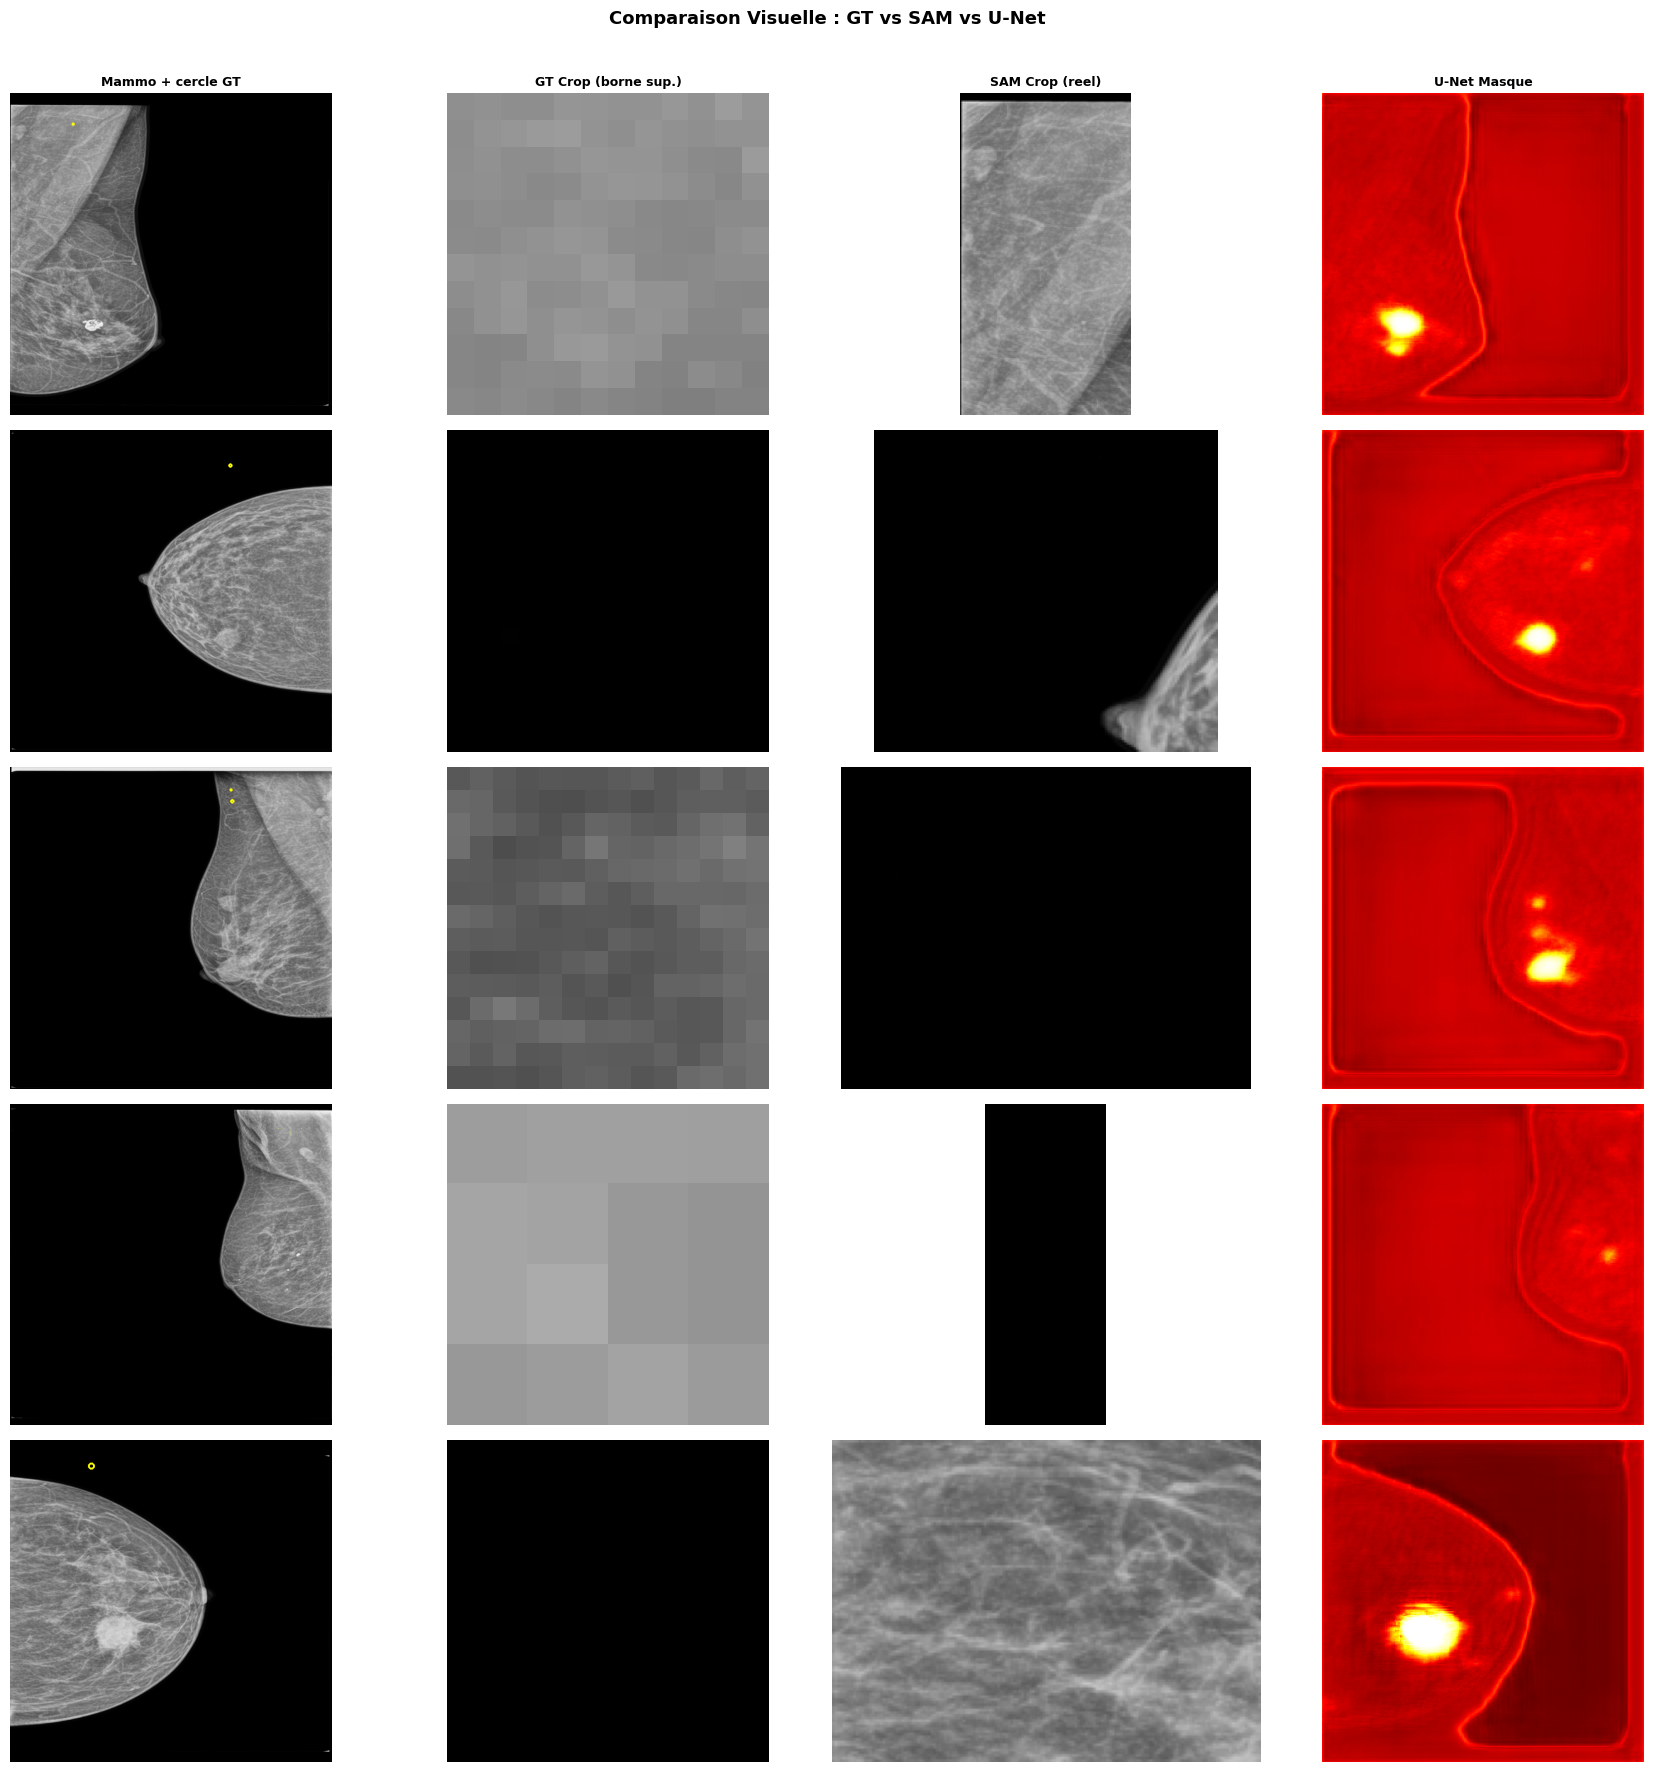

In [65]:
n_show = min(5, len(res))
fig, axes = plt.subplots(n_show, 4, figsize=(18, n_show*3.5))
if n_show==1: axes=axes[np.newaxis,:]
cols = ['Mammo + cercle GT','GT Crop (borne sup.)','SAM Crop (reel)','U-Net Masque']
for ax, t in zip(axes[0], cols):
    ax.set_title(t, fontsize=9, fontweight='bold')

for i, row in res.head(n_show).iterrows():
    path = get_img_path(row['ref'])
    if path is None: continue
    img  = Image.open(path).convert('RGB')
    meta_les = test_df[test_df['ref']==row['ref']]
    true_l = 'Malin' if row['true']==1 else 'Benin'

    # Col 0 — image entière + cercle(s) GT
    ov = img.copy(); draw = ImageDraw.Draw(ov)
    for _, r0 in meta_les.iterrows():
        cx = int(r0['cx']*COORD_SX); cy = int(r0['cy']*COORD_SY)
        rr = int(r0['radius']*min(COORD_SX,COORD_SY))
        draw.ellipse([cx-rr,cy-rr,cx+rr,cy+rr], outline='yellow', width=3)
    axes[i][0].imshow(ov); axes[i][0].axis('off')
    axes[i][0].set_ylabel(f'True:{true_l}', fontsize=8)
    axes[i][0].set_xlabel('GT circles', fontsize=8)

    # Col 1 — GT crop
    if not meta_les.empty:
        r0 = meta_les.iloc[0]
        gc = crop_gt(img, r0['cx'], r0['cy'], r0['radius'],
                     sx=COORD_SX, sy=COORD_SY)
    else:
        gc = img
    axes[i][1].imshow(gc); axes[i][1].axis('off')
    c1 = 'green' if row['gt_pred']==row['true'] else 'red'
    axes[i][1].set_xlabel(
        f"{'M' if row['gt_pred'] else 'B'} ({row['gt_prob']:.2f})",
        color=c1, fontsize=8)

    # Col 2 — SAM crop
    _,_,sb = sam_run(img)
    sc2 = img.crop(sb)
    axes[i][2].imshow(sc2); axes[i][2].axis('off')
    c2 = 'green' if row['sam_pred']==row['true'] else 'red'
    axes[i][2].set_xlabel(
        f"{'Malin' if row['sam_pred'] else 'Bénin'} ({row['sam_prob']:.2f})",
        color=c2, fontsize=9)

    # Col 3 — U-Net masque
    xt = SEG_TF(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pm = torch.sigmoid(unet(xt))[0,0].cpu().numpy()
    axes[i][3].imshow(pm, cmap='hot', vmin=0, vmax=1); axes[i][3].axis('off')

plt.suptitle('Comparaison Visuelle : GT vs SAM vs U-Net',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(PFA_PATH,'visual_comparison.png'),
            dpi=150, bbox_inches='tight')
plt.show()


In [66]:
print('='*65)
print('   SYNTHESE FINALE — PIPELINE DMID')
print('='*65)
print(f'\nDataset')
print(f'  Lesions B+M      : {len(df_bm):>4d}  (niveau segmentation)')
print(f'  Images uniques   : {df_bm["ref"].nunique():>4d}  (niveau classification)')
print(f'  Splits lésions   : {len(train_df)} train / {len(val_df)} val / {len(test_df)} test crops')
print(f'  Splits images    : {len(img_train_df)} train / {len(img_val_df)} val / {len(img_test_df)} test')
print(f'\nEfficientNet-B3 — Feature Extraction (crops GT, PAD={EFF_PAD})')
print(f'  Entree           : crop centre sur la lésion + tissu voisin')
print(f'  Classifieur      : {best_name.strip()}')
print(f'  CV AUC (5-fold)  : {best_cv:.4f}')
print(f'  Test AUC         : {te_auc:.4f}')
print(f'  Test Accuracy    : {accuracy_score(y_te, te_preds):.4f}')
print(f'  Test F1          : {f1_score(y_te, te_preds, zero_division=0):.4f}')
print(f'  (Seuil Youden    : {best_thr:.3f} — voir tableau comparatif seuils)')
print(f'\nU-Net — Segmentation (fine-tuné sur DMID)')
print(f'  Dice moy  : {np.mean(dices):.4f}')
print(f'  Exec Time : {(t1_unet-t0_unet)/len(test_seg.dataset)*1000:.1f}ms/image')
print(f'\nSegmentation — Comparaison 4 modèles')
print(f'  {"":40s} Dice')
for lbl, dices_ in [
    ('SAM original       (hotspot auto)',  sam_dices),
    ('SAM fine-tune DMID (prompt GT)',     sam_ft_dices_gt),
    ('SAM fine-tune DMID (hotspot auto)',  sam_ft_dices_hs),
    ('U-Net fine-tune DMID',              dices),
]:
    print(f'  {lbl:40s} {np.mean(dices_):.3f}')
print(f'  Gain SAM FT (GT) vs SAM original : +{np.mean(sam_ft_dices_gt)-np.mean(sam_dices):.3f} Dice')
print(f'\nPipeline End-to-End (meme classifieur EfficientNet)')
print(f'  Évaluation au niveau IMAGE ({len(res)} images test)')
def _auc2(y,p): return roc_auc_score(y,p) if len(set(y))>1 else 0.
for col_p, col_s, lbl in [
    ('gt_pred',  'gt_prob',  'GT crop   (borne sup.)'),
    ('sam_pred', 'sam_prob', 'SAM crop  (pipeline reel)'),
]:
    acc = accuracy_score(res['true'],res[col_p])
    auc = _auc2(res['true'],res[col_s])
    print(f'  {lbl:30s} Acc={acc:.3f}  AUC={auc:.3f}')
print(f'\nConclusion : U-Net fine-tuné >> SAM généraliste sur DMID')
print(f'  Le fine-tuning sur données spécifiques est indispensable')
print(f'  pour la segmentation médicale précise.')
print(f'\nModele sauvegarde : {MODELS_DIR}/effnet_classifier.pkl')
print('='*65)


   SYNTHESE FINALE — PIPELINE DMID

Dataset
  Lesions B+M      :  408  (niveau segmentation)
  Images uniques   :  274  (niveau classification)
  Splits lésions   : 280 train / 66 val / 62 test crops
  Splits images    : 191 train / 41 val / 42 test

EfficientNet-B3 — Feature Extraction (crops GT, PAD=3.0)
  Entree           : crop centre sur la lésion + tissu voisin
  Classifieur      : LogReg  C=0.1
  CV AUC (5-fold)  : 0.7465
  Test AUC         : 0.7503
  Test Accuracy    : 0.6452
  Test F1          : 0.4762
  (Seuil Youden    : 0.338 — voir tableau comparatif seuils)

U-Net — Segmentation (fine-tuné sur DMID)
  Dice moy  : 0.4658
  Exec Time : 18.7ms/image

Segmentation — Comparaison 4 modèles
                                           Dice
  SAM original       (hotspot auto)        0.091
  SAM fine-tune DMID (prompt GT)           0.429
  SAM fine-tune DMID (hotspot auto)        0.122
  U-Net fine-tune DMID                     0.466
  Gain SAM FT (GT) vs SAM original : +0.338 Dice
